In [56]:
# import the packagesand loading the csv
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("sales.csv")
df

,OrderId,Date,Product,Category,Region,Units,UnitPrice,DiscountPct
0,ORD1001,2026-01-05,Wireless Mouse,Accessories,South,2,650.0,0.00
1,ORD1002,2026-01-12,Mechanical Keyboard,Accessories,South,1,2400.0,0.05
2,ORD1003,2026-02-03,USB-C Hub,Connectivity,West,3,1250.0,0.10
3,ORD1004,2026-02-18,Monitor,Displays,North,1,8500.0,0.00
4,ORD1005,2026-03-02,Wireless Mouse,Accessories,West,4,650.0,0.05
5,ORD1006,2026-03-15,Laptop Stand,Accessories,South,2,1800.0,0.10
6,ORD1007,2026-04-07,Monitor,Displays,East,2,8500.0,0.05
7,ORD1008,2026-04-21,USB-C Hub,Connectivity,North,1,1250.0,0.00
8,ORD1009,2026-05-11,Mechanical Keyboard,Accessories,East,2,2400.0,0.10
9,ORD1010,2026-05-25,Laptop Stand,Accessories,West,3,1800.0,0.00


In [57]:
#inspecting the data
print("------------------------------------------------------------------------------")
print("Data dimensions", df.shape)
print("------------------------------------------------------------------------------")
print("Column names", df.columns.tolist())
print("------------------------------------------------------------------------------")
print(df.info())
print("------------------------------------------------------------------------------")
print(df.describe())

------------------------------------------------------------------------------
Data dimensions (10, 8)
------------------------------------------------------------------------------
Column names ['OrderId', 'Date', 'Product', 'Category', 'Region', 'Units', 'UnitPrice', 'DiscountPct']
------------------------------------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   OrderId      10 non-null     str    
 1   Date         10 non-null     str    
 2   Product      10 non-null     str    
 3   Category     10 non-null     str    
 4   Region       10 non-null     str    
 5   Units        10 non-null     int64  
 6   UnitPrice    10 non-null     float64
 7   DiscountPct  10 non-null     float64
dtypes: float64(2), int64(1), str(5)
memory usage: 772.0 bytes
None
----------------------------------------------------------

In [14]:
#Find missing values and duplicates
print(df.isnull().sum())
print("------------------------------------------------------------------------------")

# find duplicate rows
print(df.duplicated().sum())
print("------------------------------------------------------------------------------")

print(df[df.duplicated()])
print("------------------------------------------------------------------------------")
# standardize product names
df["Product"] = df["Product"].str.strip().str.title()
print("------------------------------------------------------------------------------")

#Remove exact dupicate rows
df = df.drop_duplicates()

OrderId        0
Date           0
Product        0
Category       0
Region         0
Units          0
UnitPrice      0
DiscountPct    0
dtype: int64
------------------------------------------------------------------------------
0
------------------------------------------------------------------------------
Empty DataFrame
Columns: [OrderId, Date, Product, Category, Region, Units, UnitPrice, DiscountPct]
Index: []
------------------------------------------------------------------------------
------------------------------------------------------------------------------


In [18]:
# convert incorrect datatypes
df["Date"] = pd.to_datetime(df["Date"],errors="coerce")
df["Units"] = pd.to_numeric(df["Units"],errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"],errors="coerce")
print("------------------------------------------------------------------------------")

print(df["Date"].dtype)
print("------------------------------------------------------------------------------")

print(df["UnitPrice"].dtype)
print("------------------------------------------------------------------------------")
print(df["Units"].dtype)


------------------------------------------------------------------------------
datetime64[us]
------------------------------------------------------------------------------
float64
------------------------------------------------------------------------------
int64


In [23]:
# revenue calculations and staistics

df["Revenue"] = (
    df["Units"] * df["UnitPrice"] * (1 - df["DiscountPct"])
)
print("Total revenue:", df["Revenue"].sum())
print("Average revenue:", df["Revenue"].mean())
print("Median revenue:", df["Revenue"].median())
print("Highest revenue:", df["Revenue"].max())
df

Total revenue: 48285.0
Average revenue: 4828.5
Median revenue: 3307.5
Highest revenue: 16150.0


,OrderId,Date,Product,Category,Region,Units,UnitPrice,DiscountPct,Revenue
0,ORD1001,2026-01-05,Wireless Mouse,Accessories,South,2,650.0,0.00,1300.0
1,ORD1002,2026-01-12,Mechanical Keyboard,Accessories,South,1,2400.0,0.05,2280.0
2,ORD1003,2026-02-03,Usb-C Hub,Connectivity,West,3,1250.0,0.10,3375.0
3,ORD1004,2026-02-18,Monitor,Displays,North,1,8500.0,0.00,8500.0
4,ORD1005,2026-03-02,Wireless Mouse,Accessories,West,4,650.0,0.05,2470.0
5,ORD1006,2026-03-15,Laptop Stand,Accessories,South,2,1800.0,0.10,3240.0
6,ORD1007,2026-04-07,Monitor,Displays,East,2,8500.0,0.05,16150.0
7,ORD1008,2026-04-21,Usb-C Hub,Connectivity,North,1,1250.0,0.00,1250.0
8,ORD1009,2026-05-11,Mechanical Keyboard,Accessories,East,2,2400.0,0.10,4320.0
9,ORD1010,2026-05-25,Laptop Stand,Accessories,West,3,1800.0,0.00,5400.0


In [26]:
# Outlier detection
Q1 = df["UnitPrice"].quantile(0.25)
Q3 = df["UnitPrice"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["UnitPrice"] < lower_limit) |
    (df["UnitPrice"] > upper_limit)
]

print(outliers)

   OrderId       Date  Product  Category Region  Units  UnitPrice  \
3  ORD1004 2026-02-18  Monitor  Displays  North      1     8500.0   
6  ORD1007 2026-04-07  Monitor  Displays   East      2     8500.0   

   DiscountPct  Revenue  
3         0.00   8500.0  
6         0.05  16150.0  


In [36]:
# grouping and aggregations
print(df.groupby("Category")["Revenue"].sum())
print("---------------------------# revenue by region---------------------------------------------------")
revenue_by_region = (
    df.groupby("Region")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)
print(revenue_by_region)

print("---------------------------# Region summary---------------------------------------------------")
region_summary = (
    df.groupby("Region")
    .agg(
        TotalRevenue=("Revenue","sum"),
        AverageRevenue=("Revenue","mean"),
        OrderCount=("OrderId","count"),
        TotalUnits=("Units","sum"),
        MinimumRevenue=("Revenue","min"),
        MaxRevenue=("Revenue","max")
    ).sort_values("TotalRevenue",ascending=False)
)
print(region_summary)
print("---------------------------# Product summary---------------------------------------------------")

product_summary = (
    df.groupby("Product")
      .agg(
          TotalRevenue=("Revenue", "sum"),
          AverageRevenue=("Revenue", "mean"),
          TotalUnits=("Units", "sum"),
          TransactionCount=("OrderId", "count"),
          AverageUnitPrice=("UnitPrice", "mean"),
          MaximumRevenue=("Revenue", "max")
      )
      .sort_values("TotalRevenue", ascending=False)
)

print(product_summary)

Category
Accessories     19010.0
Connectivity     4625.0
Displays        24650.0
Name: Revenue, dtype: float64
---------------------------# revenue by region---------------------------------------------------
Region
East     20470.0
West     11245.0
North     9750.0
South     6820.0
Name: Revenue, dtype: float64
---------------------------# Region summary---------------------------------------------------
        TotalRevenue  AverageRevenue  OrderCount  TotalUnits  MinimumRevenue  \
Region                                                                         
East         20470.0    10235.000000           2           4          4320.0   
West         11245.0     3748.333333           3          10          2470.0   
North         9750.0     4875.000000           2           2          1250.0   
South         6820.0     2273.333333           3           5          1300.0   

        MaxRevenue  
Region              
East       16150.0  
West        5400.0  
North       8500.0  
South

In [38]:
# Reusabel summary
sales_summary = (
    df.groupby("Product")
      .agg(
          TotalRevenue=("Revenue", "sum"),
          MeanRevenue=("Revenue", "mean"),
          MedianRevenue=("Revenue", "median"),
          MinimumRevenue=("Revenue", "min"),
          MaximumRevenue=("Revenue", "max"),
          TotalUnits=("Units", "sum"),
          UniqueOrders=("OrderId", "nunique")
      )
)
print(sales_summary)

                     TotalRevenue  MeanRevenue  MedianRevenue  MinimumRevenue  \
Product                                                                         
Laptop Stand               8640.0       4320.0         4320.0          3240.0   
Mechanical Keyboard        6600.0       3300.0         3300.0          2280.0   
Monitor                   24650.0      12325.0        12325.0          8500.0   
Usb-C Hub                  4625.0       2312.5         2312.5          1250.0   
Wireless Mouse             3770.0       1885.0         1885.0          1300.0   

                     MaximumRevenue  TotalUnits  UniqueOrders  
Product                                                        
Laptop Stand                 5400.0           5             2  
Mechanical Keyboard          4320.0           3             2  
Monitor                     16150.0           3             2  
Usb-C Hub                    3375.0           4             2  
Wireless Mouse               2470.0           6 

In [65]:
#Bar chart compare categories
revenue_by_product = (
    df.groupby("Region")["Revenue"]
      .sum()
      .sort_values(ascending=False)
)

revenue_by_product.plot(
    kind="bar",
    title="Total Revenue by Product"
)

plt.xlabel("Product")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.show()

KeyError: 'Column not found: Revenue'

In [71]:
# fixing this error by converting date to datetime and fetching month from that
df["Date"]= pd.to_datetime(df["Date"],errors="coerce")
df["Month"]=  df["Date"].dt.to_period("M").astype(str)
print(df["Month"])

0    2026-01
1    2026-01
2    2026-02
3    2026-02
4    2026-03
5    2026-03
6    2026-04
7    2026-04
8    2026-05
9    2026-05
Name: Month, dtype: str


   Units  UnitPrice  DiscountPct  Revenue
0      2      650.0         0.00   1300.0
1      1     2400.0         0.05   2280.0
2      3     1250.0         0.10   3375.0
3      1     8500.0         0.00   8500.0
4      4      650.0         0.05   2470.0
5      2     1800.0         0.10   3240.0
6      2     8500.0         0.05  16150.0
7      1     1250.0         0.00   1250.0
8      2     2400.0         0.10   4320.0
9      3     1800.0         0.00   5400.0


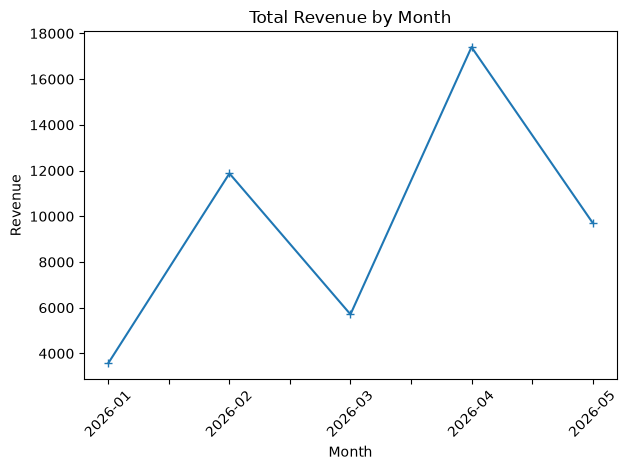

In [73]:
df["Revenue"] = (
    df["Units"] *
    df["UnitPrice"] *
    (1 - df["DiscountPct"])
)

print(df[["Units", "UnitPrice", "DiscountPct", "Revenue"]])
monthly_revenue = df.groupby("Month")["Revenue"].sum().sort_index()

monthly_revenue.plot(
    kind="line",
    marker="+",
    title="Total Revenue by Month"
)

plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

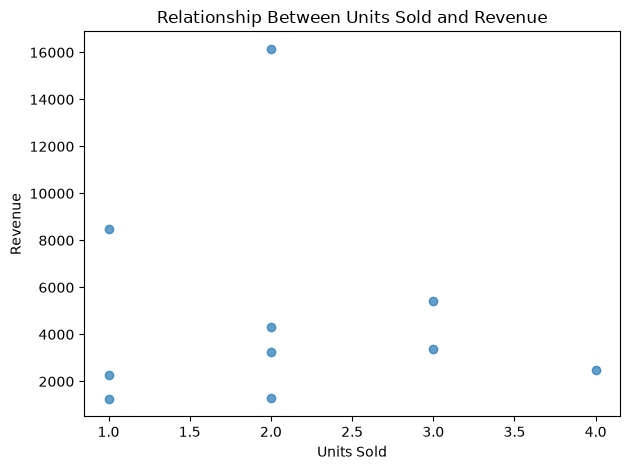

In [77]:
plt.scatter(df["Units"], df["Revenue"], alpha=0.7)

plt.title("Relationship Between Units Sold and Revenue")
plt.xlabel("Units Sold")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

In [84]:
# date amd time period analysis
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.to_period("M").astype("string")
df["Quarter"] = df["Date"].dt.to_period("Q").astype("string")
df["DayOfWeek"] = df["Date"].dt.day_name()

daily_revenue = df.groupby("Date")["Revenue"].sum()

monthly_revenue = df.groupby("Month")["Revenue"].sum()

quarterly_revenue = df.groupby("Quarter")["Revenue"].sum()

yearly_revenue = df.groupby("Year")["Revenue"].sum()

weekday_revenue = df.groupby("DayOfWeek")["Revenue"].sum()

numeric_columns = [
    "Units",
    "UnitPrice",
    "DiscountPct",
    "Revenue"
]

print("------------------------------------------------------------------------------")

print(daily_revenue)
print("------------------------------------------------------------------------------")

print(monthly_revenue)
print("------------------------------------------------------------------------------")

print(quarterly_revenue)
print("------------------------------------------------------------------------------")

print(yearly_revenue)
print("------------------------------------------------------------------------------")

print(weekday_revenue)

------------------------------------------------------------------------------
Date
2026-01-05     1300.0
2026-01-12     2280.0
2026-02-03     3375.0
2026-02-18     8500.0
2026-03-02     2470.0
2026-03-15     3240.0
2026-04-07    16150.0
2026-04-21     1250.0
2026-05-11     4320.0
2026-05-25     5400.0
Name: Revenue, dtype: float64
------------------------------------------------------------------------------
Month
2026-01     3580.0
2026-02    11875.0
2026-03     5710.0
2026-04    17400.0
2026-05     9720.0
Name: Revenue, dtype: float64
------------------------------------------------------------------------------
Quarter
2026Q1    21165.0
2026Q2    27120.0
Name: Revenue, dtype: float64
------------------------------------------------------------------------------
Year
2026    48285.0
Name: Revenue, dtype: float64
------------------------------------------------------------------------------
DayOfWeek
Monday       15770.0
Sunday        3240.0
Tuesday      20775.0
Wednesday     8500.0
